In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns

In [2]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler 

In [8]:
from tensorflow.keras.datasets import mnist
from sklearn.decomposition import PCA
import os
filename="mnist_train.csv"
downloads_path=os.path.join(os.path.expanduser("~"),"Downloads")
file_path=os.path.join(downloads_path,filename)
df= pd.read_csv(file_path)
y_train = df.iloc[:,0].values
X_train_flat=df.iloc[:,1:].values
 
unique_labels, label_count = np.unique(y_train, return_counts=True)
print(f"Unique labels: {unique_labels}")
print(f"Number of samples per label")
for label_count in zip(unique_labels, label_count):
    print(f"{label_count[0]}: {label_count[1]}")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
plt.figure(figsize=(10, 10))
for i in range(1,6):
    
    pca_all = PCA(n_components=i)
    pca_all_fit=pca_all.fit_transform(X_train_scaled)
    print(f"Completed PCA processing for component length: {i}")

Unique labels: [0 1 2 3 4 5 6 7 8 9]
Number of samples per label
0: 309
1: 363
2: 326
3: 318
4: 357
5: 292
6: 328
7: 356
8: 294
9: 316
Completed PCA processing for component length: 1
Completed PCA processing for component length: 2
Completed PCA processing for component length: 3
Completed PCA processing for component length: 4
Completed PCA processing for component length: 5


<Figure size 1000x1000 with 0 Axes>

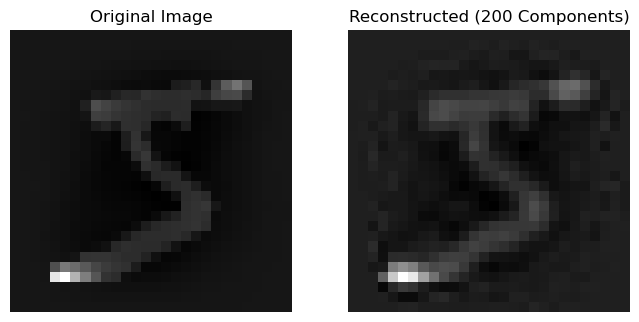

In [13]:
pca_50=PCA(n_components=200)
X_train_pca50=pca_50.fit_transform(X_train_scaled)
X_train_pca_recon=pca_50.inverse_transform(X_train_pca50)
try:
    img_shape=int(X_train_scaled.shape[1]**0.5)
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1)
    plt.imshow(X_train_scaled[0].reshape(img_shape,img_shape),cmap='gray')
    plt.title('Original Image')
    plt.axis('off')
    plt.subplot(1,2,2)
    plt.imshow(X_train_pca_recon[0].reshape(img_shape,img_shape),cmap='gray')
    plt.title('Reconstructed (200 Components)')
    plt.axis('off')
    plt.show()
except Exception as e:
    print("Count not plot image,Dimensionality might be different:",e)